# Dempster-Shafer Evidence Fusion for Target Classification from Multiple Conflicting Sensors

### EN.605.745 Reasoning Under Uncertainty
### Adam Lane

This notebook walks through the implementation in the `dsfusion` package. It first traces the reasoning step by hand on a small case so every intermediate belief mass is visible, then runs the validation suite, then fuses one simulated contact, and finally runs the reliability and conflict sweep that compares Dempster-Shafer fusion with the naive Bayes baseline. Run instructions for the scripts are in `README.md`. Every cell runs top to bottom in a few seconds with the fixed seed `605745`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))
import numpy as np
import pandas as pd
from IPython.display import Image, display

from dsfusion.core import (subset, full_frame, make_mass, discount, dempster_combine,
                           combine_all, total_conflict, belief, plausibility, pignistic, label)
from dsfusion.bayes import naive_bayes_fuse, mass_to_likelihood
from dsfusion.simulator import CLASS_NAMES, SENSORS
n, TH = 4, full_frame(4)
show = lambda m: {label(A, CLASS_NAMES, n): round(v, 6) for A, v in sorted(m.items(), key=lambda kv: -kv[1])}

---

## **1. The Reasoning Step, Traced on a Small Case**

The frame of discernment is Θ = {F, T, H, U}, and each subset is stored as a 4 bit integer. A mass function may place belief on any nonempty subset, and mass on Θ itself represents what the sensor does not know. The case below is test T5 in the suite. Sensor 1 points at {F} but is believed reliable only 75 percent of the time, so it is discounted by 0.25. Sensor 2 can narrow the contact only to {F, T}. Sensor 3 disagrees and points at {H}.

In [2]:
r1 = make_mass([(subset(0), 0.8), (TH, 0.2)])      # {F}
r2 = make_mass([(subset(0, 1), 0.7), (TH, 0.3)])   # {F,T}, a set the sensor cannot split
r3 = make_mass([(subset(2), 0.5), (TH, 0.5)])      # {H}, the conflicting report
d1 = discount(r1, 0.25, n)
print("Sensor 1 (Discounted by 0.25):", show(d1))
m12, K1 = dempster_combine(d1, r2)
print("Sensors 1 and 2:", show(m12), " K =", round(K1, 6))
m, K2 = dempster_combine(m12, r3)
print("Sensors 1, 2, and 3:", show(m), " K =", round(K2, 6))

Sensor 1 (Discounted by 0.25): {'{F}': 0.6, 'Theta': 0.4}
Sensors 1 and 2: {'{F}': 0.6, '{F,T}': 0.28, 'Theta': 0.12}  K = 0.0
Sensors 1, 2, and 3: {'{F}': 0.535714, '{F,T}': 0.25, '{H}': 0.107143, 'Theta': 0.107143}  K = 0.44


Combining sensors 1 and 2 produces no conflict, because every pair of focal sets intersects. Adding sensor 3 sends 0.30 + 0.14 = 0.44 of the product mass to the empty set. Dempster's rule records that as the conflict K and renormalizes the surviving 0.56. The conflict is not hidden, and it is returned alongside the combined mass so that it can be reported and analyzed. The table below reads the combined mass three ways. Belief is the mass committed to a class, plausibility is the mass that does not contradict it, and the pignistic probability shares each set's mass equally among its members at decision time.

In [3]:
betp = pignistic(m, n)
bayes_plain = naive_bayes_fuse([r1, r2, r3], n)
bayes_disc = naive_bayes_fuse([r1, r2, r3], n, alphas=[0.25, 0.0, 0.0])
print("Belief, Plausibility, and Fused Posteriors by Class for the Traced Case")
pd.DataFrame({
    "Bel": [belief(m, 1 << i) for i in range(n)],
    "Pl": [plausibility(m, 1 << i) for i in range(n)],
    "BetP (DS)": betp,
    "Naive Bayes": bayes_plain,
    "Naive Bayes (Discounted)": bayes_disc,
}, index=CLASS_NAMES).round(4)

Belief, Plausibility, and Fused Posteriors by Class for the Traced Case


,Bel,Pl,BetP (DS),Naive Bayes,Naive Bayes (Discounted)
F,0.5357,0.8929,0.6875,0.8920,0.7727
T,0.0000,0.3571,0.1518,0.0525,0.1104
H,0.1071,0.2143,0.1339,0.0463,0.0974
U,0.0000,0.1071,0.0268,0.0093,0.0195


Every value matches the hand derivation in `README.md`. The comparison already shows the behavior the project studies. Evidence fusion gives F a probability of 0.69 and keeps an interval [0.54, 0.89] that reflects both the unresolved {F, T} support and the 0.44 conflict. Plain naive Bayes gives F 0.89, because it must spread the {F, T} report evenly across both classes and its normalization removes the disagreement without a trace.

---

## **2. Zadeh's Example and the Role of Discounting**

Zadeh's well known example has two sources that each consider a tumor nearly impossible but disagree about everything else. With fully trusted sources, Dempster's rule returns certainty in the tumor. The cell below shows that plain naive Bayes returns the same answer, so the pathology belongs to normalizing a product of nearly contradictory evidence and not to evidence theory alone. A small discount on each source restores the sensible answer.

In [4]:
M, Cc, Tm = subset(0), subset(1), subset(2)
z1 = make_mass([(M, 0.99), (Tm, 0.01)]); z2 = make_mass([(Cc, 0.99), (Tm, 0.01)])
mz, Kz = dempster_combine(z1, z2)
names3 = ["Men", "Con", "Tum"]
print("Dempster (Trusted):", {label(A, names3, 3): round(v, 6) for A, v in mz.items()}, " K =", round(Kz, 6))
print("Naive Bayes (Trusted):", np.round(naive_bayes_fuse([z1, z2], 3), 6))
mzd, Kzd = dempster_combine(discount(z1, 0.1, 3), discount(z2, 0.1, 3))
print("Dempster (Discount 0.1):", {label(A, names3, 3): round(v, 6) for A, v in mzd.items()}, " K =", round(Kzd, 6))

Dempster (Trusted): {'{Tum}': 1.0}  K = 0.9999
Naive Bayes (Trusted): [0. 0. 1.]
Dempster (Discount 0.1): {'{Men}': 0.468748, '{Tum}': 0.009896, '{Con}': 0.468748, 'Theta': 0.052609}  K = 0.809919


---

## **3. Validation Suite**

The suite holds 16 tests in seven groups. T1 is Zadeh's example, T2 is three fully agreeing sensors, T3 covers the vacuous mass and the discount endpoints, T4 checks commutativity, associativity, normalization and Bel ≤ BetP ≤ Pl on 200 random cases, T5 is the hand traced case above, T6 checks the metrics, seed reproducibility, and the clean sensor limit, and T7 asserts every row of the expected versus observed table shown below. The expected values in T1, T2, T3, T5 and T6 were derived by hand before the code was run, and the arithmetic is written out in `README.md`.

In [5]:
import unittest, tests.test_fusion as tf
result = unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromModule(tf))
print(f"Ran {result.testsRun} Tests, Failures {len(result.failures)}, and Errors {len(result.errors)}")

.....

...........
----------------------------------------------------------------------
Ran 16 tests in 0.177s

OK


Ran 16 Tests, Failures 0, and Errors 0


The table below lists every hand derived value next to the value the implementation returns. The expected column was computed on paper from the definitions of discounting, Dempster's rule, belief, plausibility, the pignistic transform, the naive Bayes product, and the Brier score. The observed column is produced by the code at run time. The largest absolute difference across all rows is at the level of floating point rounding.

In [6]:
from dsfusion.validation import validation_rows
vt = pd.DataFrame(validation_rows(), columns=["Test Case", "Quantity", "Expected (By Hand)", "Observed (Code)"])
vt["Abs Difference"] = (vt["Expected (By Hand)"] - vt["Observed (Code)"]).abs()
vt["Match to 1e-6"] = np.where(vt["Abs Difference"] < 1e-6, "yes", "NO")
print(f"{len(vt)} rows, all match: {(vt['Match to 1e-6'] == 'yes').all()}, largest difference {vt['Abs Difference'].max():.1e}")
print("\nHand-Derived Expected Values versus Code Output for the Validation Suite")
with pd.option_context("display.float_format", "{:.6f}".format, "display.max_rows", 100):
    display(vt.style.format({"Expected (By Hand)": "{:.6f}", "Observed (Code)": "{:.6f}", "Abs Difference": "{:.1e}"}).hide(axis="index"))

31 rows, all match: True, largest difference 1.1e-13

Hand-Derived Expected Values versus Code Output for the Validation Suite


Test Case,Quantity,Expected (By Hand),Observed (Code),Abs Difference,Match to 1e-6
"T1 Zadeh, trusted",K,0.999900,0.999900,0.0e+00,yes
"T1 Zadeh, trusted",m({T}),1.000000,1.000000,1.1e-13,yes
"T1 Zadeh, trusted",Bayes P(T),1.000000,1.000000,0.0e+00,yes
"T1 Zadeh, discount 0.1",K,0.809919,0.809919,1.1e-16,yes
"T1 Zadeh, discount 0.1",m({M}) = m({C}),0.468748,0.468748,2.2e-16,yes
"T1 Zadeh, discount 0.1",m({T}),0.009896,0.009896,3.5e-18,yes
"T1 Zadeh, discount 0.1",m(Theta),0.052609,0.052609,2.8e-17,yes
T2 agreeing sensors,overall K,0.000000,0.000000,0.0e+00,yes
T2 agreeing sensors,m({F}),0.992000,0.992000,3.3e-16,yes
T2 agreeing sensors,m(Theta),0.008000,0.008000,1.7e-18,yes


---

## **4. One Simulated Contact**

The simulator draws a contact with a known true class and asks three sensors for reports. Each sensor sometimes resolves the contact only to a two class group, and the three sensors group the classes differently. With probability `alpha` a sensor malfunctions and points at a random class, and otherwise with probability `c` it is deceived and points at a decoy. The worked trace below is printed by `run_experiment.py` and is reproduced from the same seed.

In [7]:
from run_experiment import worked_trace
worked_trace(alpha=0.30, conflict=0.30, seed=605745)

WORKED TRACE   alpha = 0.3, conflict c = 0.3, true class = T
Radar    [honest    ] raw: m({T})=0.800, m(Theta)=0.200
                      discounted: m({T})=0.560, m(Theta)=0.440
Imaging  [honest    ] raw: m({T})=0.850, m(Theta)=0.150
                      discounted: m({T})=0.595, m(Theta)=0.405
ESM      [decoy     ] raw: m({U})=0.700, m(Theta)=0.300
                      discounted: m({U})=0.490, m(Theta)=0.510

Step conflicts K_i = [0.0, 0.4027], overall K = 0.4027
Combined mass (Dempster's rule, normalised):
   m({T}) = 0.7017
   m(Theta) = 0.1522
   m({U}) = 0.1462

 class    Bel     Pl    BetP  Bayes  BayesDisc
   F    0.0000 0.1522 0.0380 0.0024  0.0205
   T    0.7017 0.8538 0.7397 0.9703  0.8596
   H    0.0000 0.1522 0.0380 0.0024  0.0205
   U    0.1462 0.2983 0.1842 0.0249  0.0994
Ignorance kept on Theta: m(Theta) = 0.1522



The deceived ESM report produces a conflict of 0.40 against the two agreeing reports. Evidence fusion keeps 0.15 on Θ and gives the true class T a probability of 0.74. Plain naive Bayes gives T 0.97. Both choose T, so they tie on accuracy for this contact, but they would be scored very differently by the Brier score if the decoy had been the truth. Whether that caution pays off on average is an empirical question answered by the sweep.

---

## **5. Reliability and Conflict Sweep**

The grid crosses six discount levels (0.00 to 0.75) with six conflict levels (0.0 to 0.5), and runs 2,000 Monte Carlo contacts in every cell. All three methods fuse identical reports, so the per contact differences are paired and their confidence intervals are tight.

In [8]:
from dsfusion.experiment import run_grid, summarise
rows = summarise(run_grid(verbose=False))
df = pd.DataFrame(rows)
cols = ["alpha", "conflict", "acc_DS", "acc_Bayes", "brier_DS", "brier_Bayes", "brier_BayesDisc",
        "dbrier_DS_Bayes", "dbrier_DS_Bayes_ci", "dbrier_DS_BayesDisc", "dbrier_DS_BayesDisc_ci", "K_mean"]
print("Reliability and Conflict Sweep Summary for Selected Cells")
headers = {"alpha": "Alpha", "conflict": "Conflict", "acc_DS": "Accuracy DS", "acc_Bayes": "Accuracy Bayes",
           "brier_DS": "Brier DS", "brier_Bayes": "Brier Bayes", "brier_BayesDisc": "Brier Disc. Bayes",
           "dbrier_DS_Bayes": "ΔBrier DS − Bayes", "dbrier_DS_Bayes_ci": "ΔBrier DS − Bayes CI",
           "dbrier_DS_BayesDisc": "ΔBrier DS − Disc. Bayes", "dbrier_DS_BayesDisc_ci": "ΔBrier DS − Disc. Bayes CI",
           "K_mean": "Mean Conflict K"}
df[df.alpha.isin([0.0, 0.3, 0.6]) & df.conflict.isin([0.0, 0.2, 0.4, 0.5])][cols].round(3).rename(columns=headers)

Reliability and Conflict Sweep Summary for Selected Cells


,Alpha,Conflict,Accuracy DS,Accuracy Bayes,Brier DS,Brier Bayes,Brier Disc. Bayes,ΔBrier DS − Bayes,ΔBrier DS − Bayes CI,ΔBrier DS − Disc. Bayes,ΔBrier DS − Disc. Bayes CI,Mean Conflict K
0,0.0,0.0,1.000,1.000,0.001,0.000,0.000,0.001,0.000,0.001,0.000,0.000
2,0.0,0.2,0.845,0.844,0.211,0.208,0.208,0.003,0.004,0.003,0.004,0.309
4,0.0,0.4,0.646,0.652,0.494,0.508,0.508,-0.014,0.005,-0.014,0.005,0.493
5,0.0,0.5,0.522,0.525,0.680,0.713,0.713,-0.033,0.005,-0.033,0.005,0.548
12,0.3,0.0,0.824,0.824,0.255,0.239,0.235,0.015,0.008,0.020,0.004,0.185
14,0.3,0.2,0.696,0.701,0.413,0.434,0.406,-0.021,0.010,0.007,0.004,0.262
16,0.3,0.4,0.550,0.554,0.586,0.663,0.602,-0.077,0.012,-0.016,0.005,0.307
17,0.3,0.5,0.416,0.419,0.730,0.870,0.769,-0.140,0.012,-0.039,0.005,0.326
24,0.6,0.0,0.590,0.590,0.551,0.597,0.535,-0.046,0.018,0.016,0.003,0.110
26,0.6,0.2,0.496,0.496,0.624,0.736,0.622,-0.111,0.019,0.003,0.003,0.119


In [9]:
print("Max |Accuracy Gap|, DS versus Plain Bayes:", round(float((df.dacc_DS_Bayes).abs().max()), 4))
sig = lambda d, c: np.where(d + c < 0, "DS Better", np.where(d - c > 0, "DS Worse", "ns"))
df["vs_plain"] = sig(df.dbrier_DS_Bayes, df.dbrier_DS_Bayes_ci)
df["vs_disc"] = sig(df.dbrier_DS_BayesDisc, df.dbrier_DS_BayesDisc_ci)
print("\nBrier Score Comparison, DS versus Plain Bayes (Rows Alpha, Columns Conflict)")
print(df.pivot(index="alpha", columns="conflict", values="vs_plain").rename_axis(index="Alpha", columns="Conflict"))
print("\nBrier Score Comparison, DS versus Discounted Bayes (Rows Alpha, Columns Conflict)")
print(df.pivot(index="alpha", columns="conflict", values="vs_disc").rename_axis(index="Alpha", columns="Conflict"))

Max |Accuracy Gap|, DS versus Plain Bayes: 0.012

Brier Score Comparison, DS versus Plain Bayes (Rows Alpha, Columns Conflict)
Conflict        0.0        0.1        0.2        0.3        0.4        0.5
Alpha                                                                     
0.00       DS Worse   DS Worse         ns         ns  DS Better  DS Better
0.15       DS Worse   DS Worse         ns  DS Better  DS Better  DS Better
0.30       DS Worse         ns  DS Better  DS Better  DS Better  DS Better
0.45             ns         ns  DS Better  DS Better  DS Better  DS Better
0.60      DS Better  DS Better  DS Better  DS Better  DS Better  DS Better
0.75      DS Better  DS Better  DS Better  DS Better  DS Better  DS Better

Brier Score Comparison, DS versus Discounted Bayes (Rows Alpha, Columns Conflict)
Conflict       0.0       0.1       0.2        0.3        0.4        0.5
Alpha                                                                  
0.00      DS Worse  DS Worse        ns        

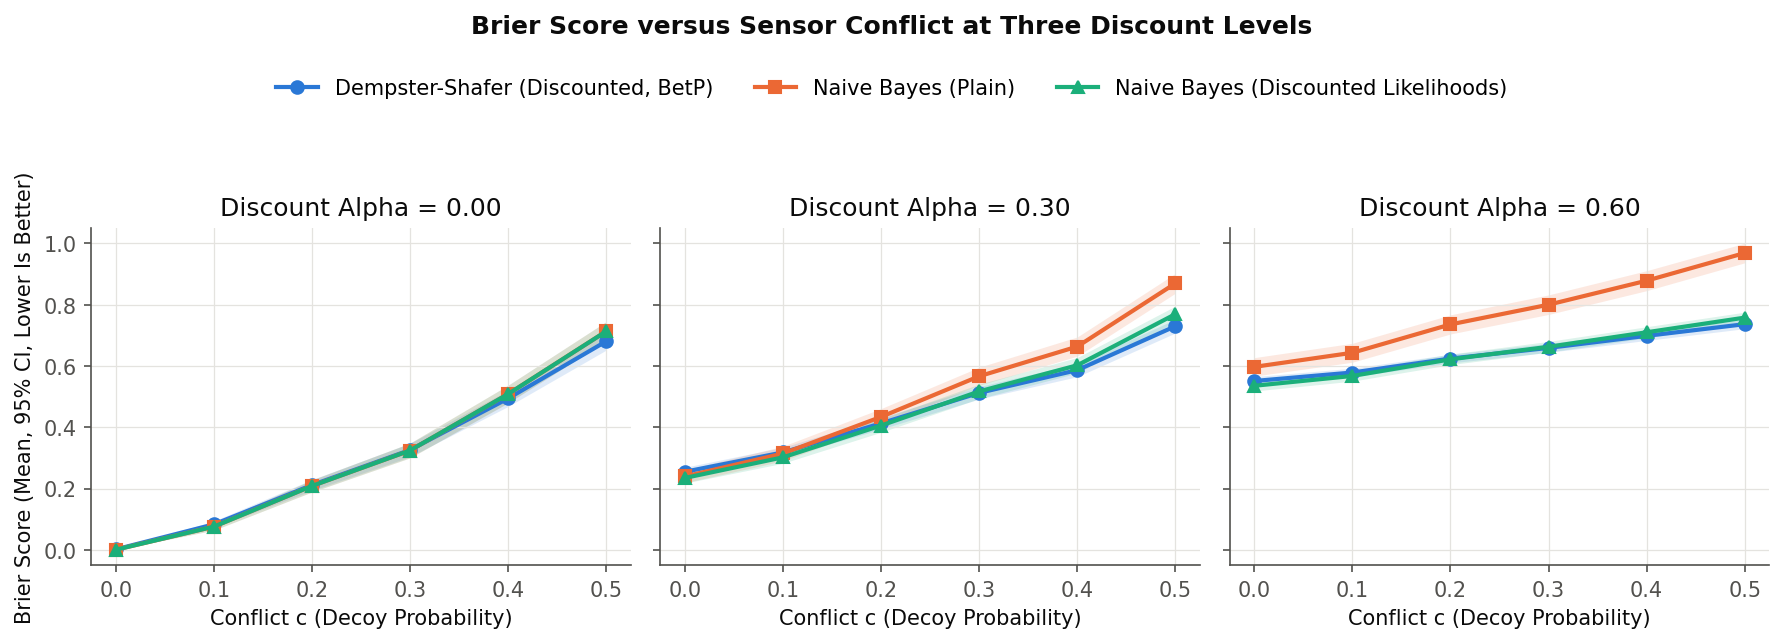

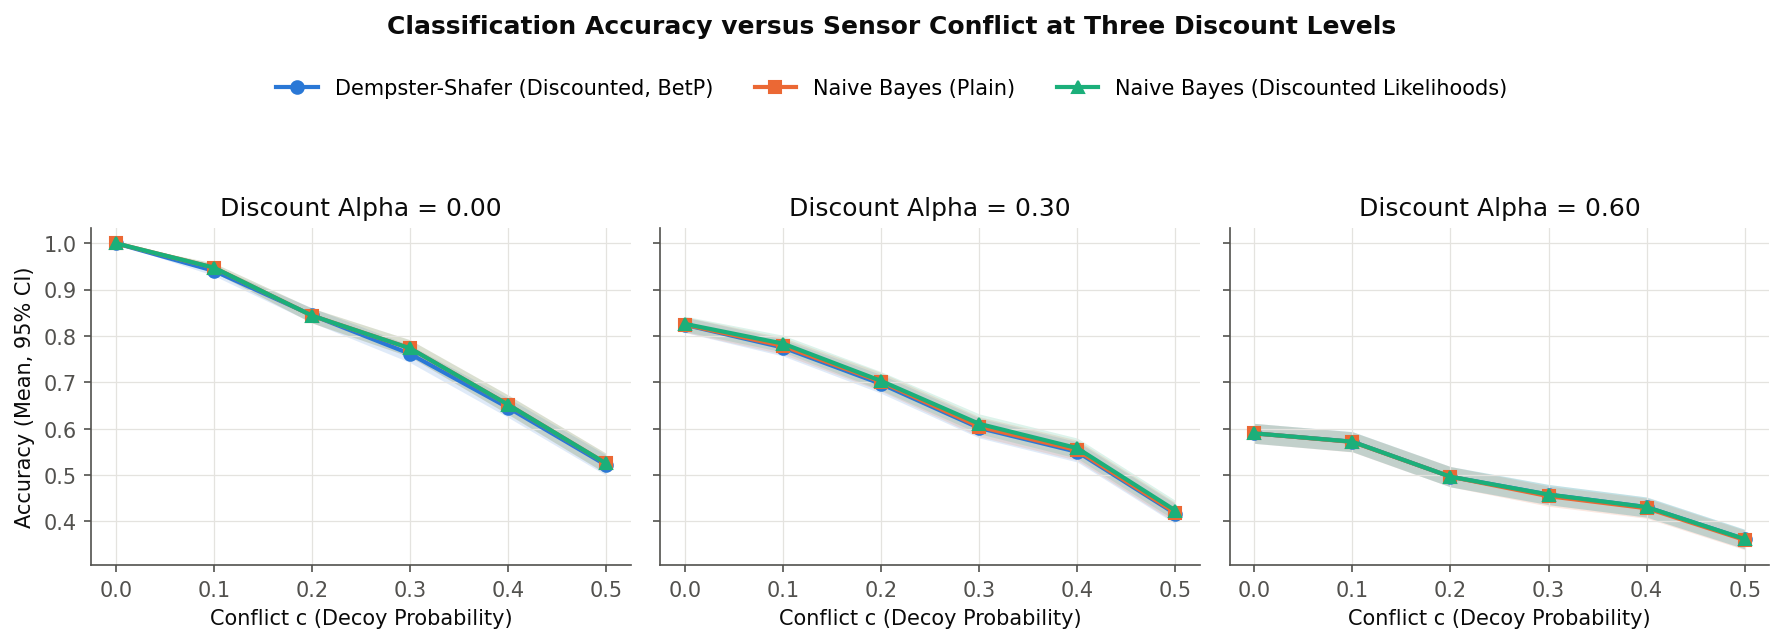

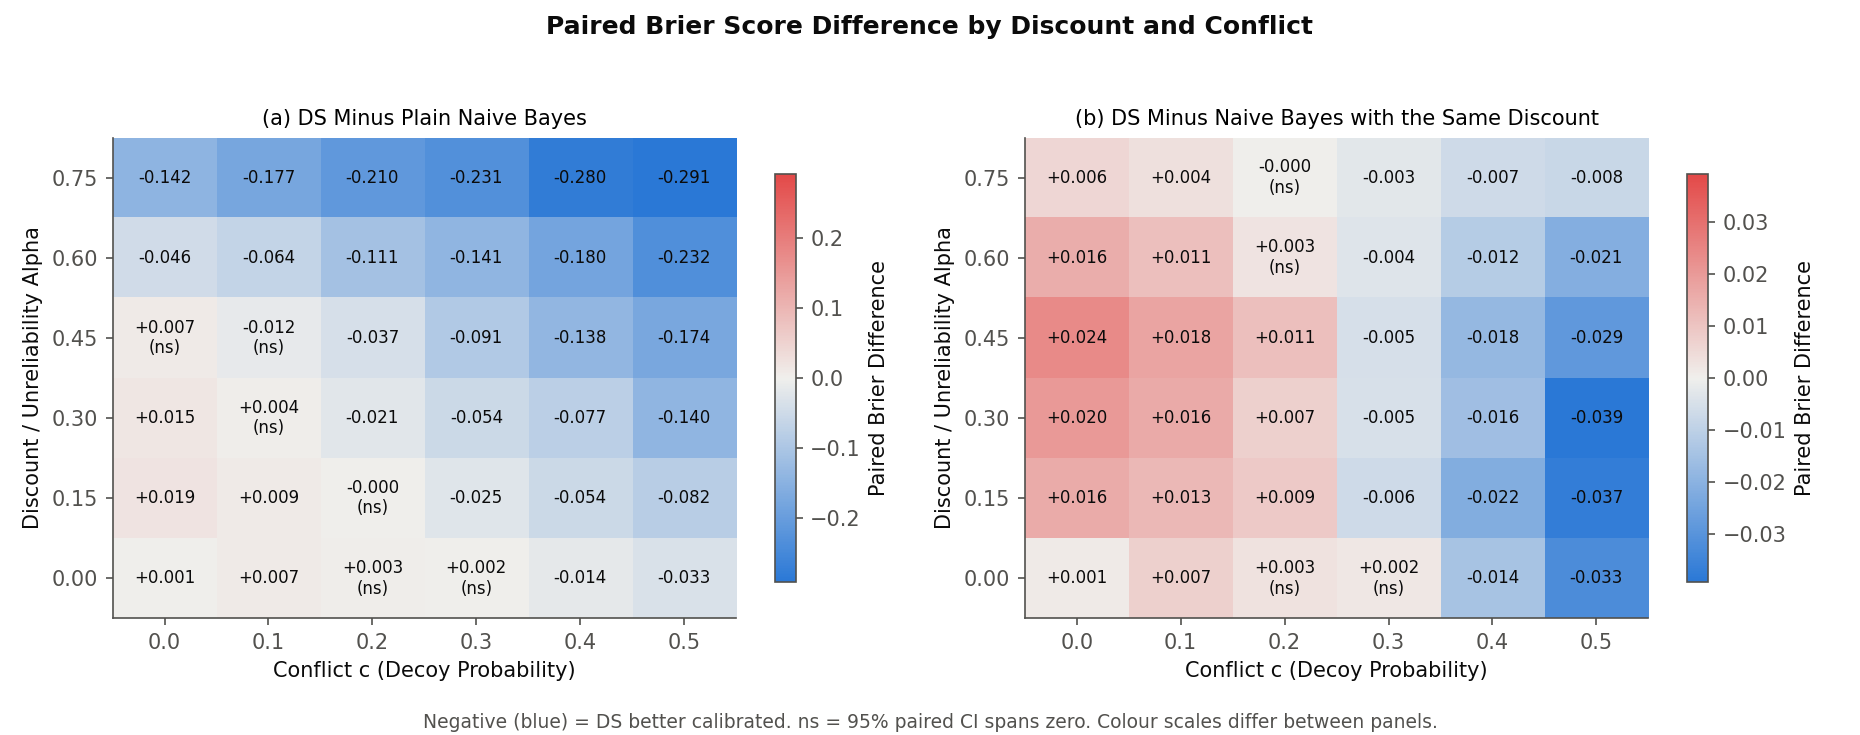

In [10]:
for f in ["fig_brier_vs_conflict.png", "fig_accuracy_vs_conflict.png", "fig_brier_difference_heatmap.png"]:
    display(Image(filename=os.path.join("results", f)))

Panel (a) of the heat map compares evidence fusion with plain naive Bayes and is blue almost everywhere outside the reliable, low conflict corner. Panel (b) is the fairer comparison, against naive Bayes given the same discount, and it shows a clean crossover. The left columns are red, meaning discounted Bayes is better calibrated when sensors rarely disagree, and the right columns are blue, meaning evidence fusion is better once conflict reaches 0.3. The two panels use separate colour scales because the gaps in (b) are roughly ten times smaller.

---

## **6. Testing an Assumption, a Misspecified Discount**

The main grid tells the fusion the true unreliability. This favors both methods that discount, because the simulator generates unreliability exactly the way Shafer discounting models it. The study below removes that advantage. For each true unreliability and conflict level, the same 2,000 contacts are fused under every assumed discount from 0.00 to 0.75, so all comparisons across assumed values and across methods are paired. Plain Bayes ignores the discount and is a fixed reference.

In [11]:
from dsfusion.experiment import run_misspec
ms = pd.DataFrame(run_misspec())
ref = ms[ms.misspec.abs() < 1e-9].set_index(["alpha_true", "conflict"])
def penalty(k, off):
    sub = ms[(ms.misspec - off).abs() < 1e-9]
    return float((sub[f"brier_{k}"].values - ref.loc[list(zip(sub.alpha_true, sub.conflict)), f"brier_{k}"].values).mean())
print("Brier Score Increase from a Misjudged Discount, Averaged over True Alpha and Conflict")
display(pd.DataFrame({off: {name: penalty(k, off) for k, name in (("DS", "Dempster-Shafer"), ("BayesDisc", "Naive Bayes (Discounted)"))} for off in (-0.30, -0.15, 0.15, 0.30)})
        .rename(columns=lambda o: f"Assumed - True = {o:+.2f}").round(3))

sig = lambda d, c: np.where(d + c < 0, "DS Better", np.where(d - c > 0, "DS Worse", "ns"))
ms["vs_disc"] = sig(ms.dbrier_DS_BayesDisc, ms.dbrier_DS_BayesDisc_ci)
ms["direction"] = np.select([ms.misspec < -1e-9, ms.misspec > 1e-9], ["too small", "too large"], "correct")
print(); print("DS versus Discounted Bayes by Direction of the Error (Count of Cells)")
display(pd.crosstab(ms.direction, ms.vs_disc).loc[["too small", "correct", "too large"]]
        .rename(index=str.title).rename_axis(index="Direction of Error", columns="DS versus Discounted Bayes"))

best = ms.loc[ms.groupby(["alpha_true", "conflict"]).brier_DS.idxmin(), ["alpha_true", "conflict", "alpha_assumed"]]
print(); print("Assumed Discount That Minimises the DS Brier Score")
display(best.pivot(index="alpha_true", columns="conflict", values="alpha_assumed").rename_axis(index="True Alpha", columns="Conflict"))

Brier Score Increase from a Misjudged Discount, Averaged over True Alpha and Conflict


,Assumed - True = -0.30,Assumed - True = -0.15,Assumed - True = +0.15,Assumed - True = +0.30
Dempster-Shafer,0.028,0.01,0.005,0.026
Naive Bayes (Discounted),0.049,0.02,-0.007,0.003



DS versus Discounted Bayes by Direction of the Error (Count of Cells)


DS versus Discounted Bayes,DS Better,DS Worse,ns
Direction of Error,,,
Too Small,24,3,3
Correct,7,4,1
Too Large,5,21,4



Assumed Discount That Minimises the DS Brier Score


Conflict,0.0,0.3,0.5
True Alpha,,,
0.15,0.00,0.30,0.60
0.30,0.00,0.30,0.60
0.45,0.15,0.45,0.75
0.60,0.30,0.60,0.75


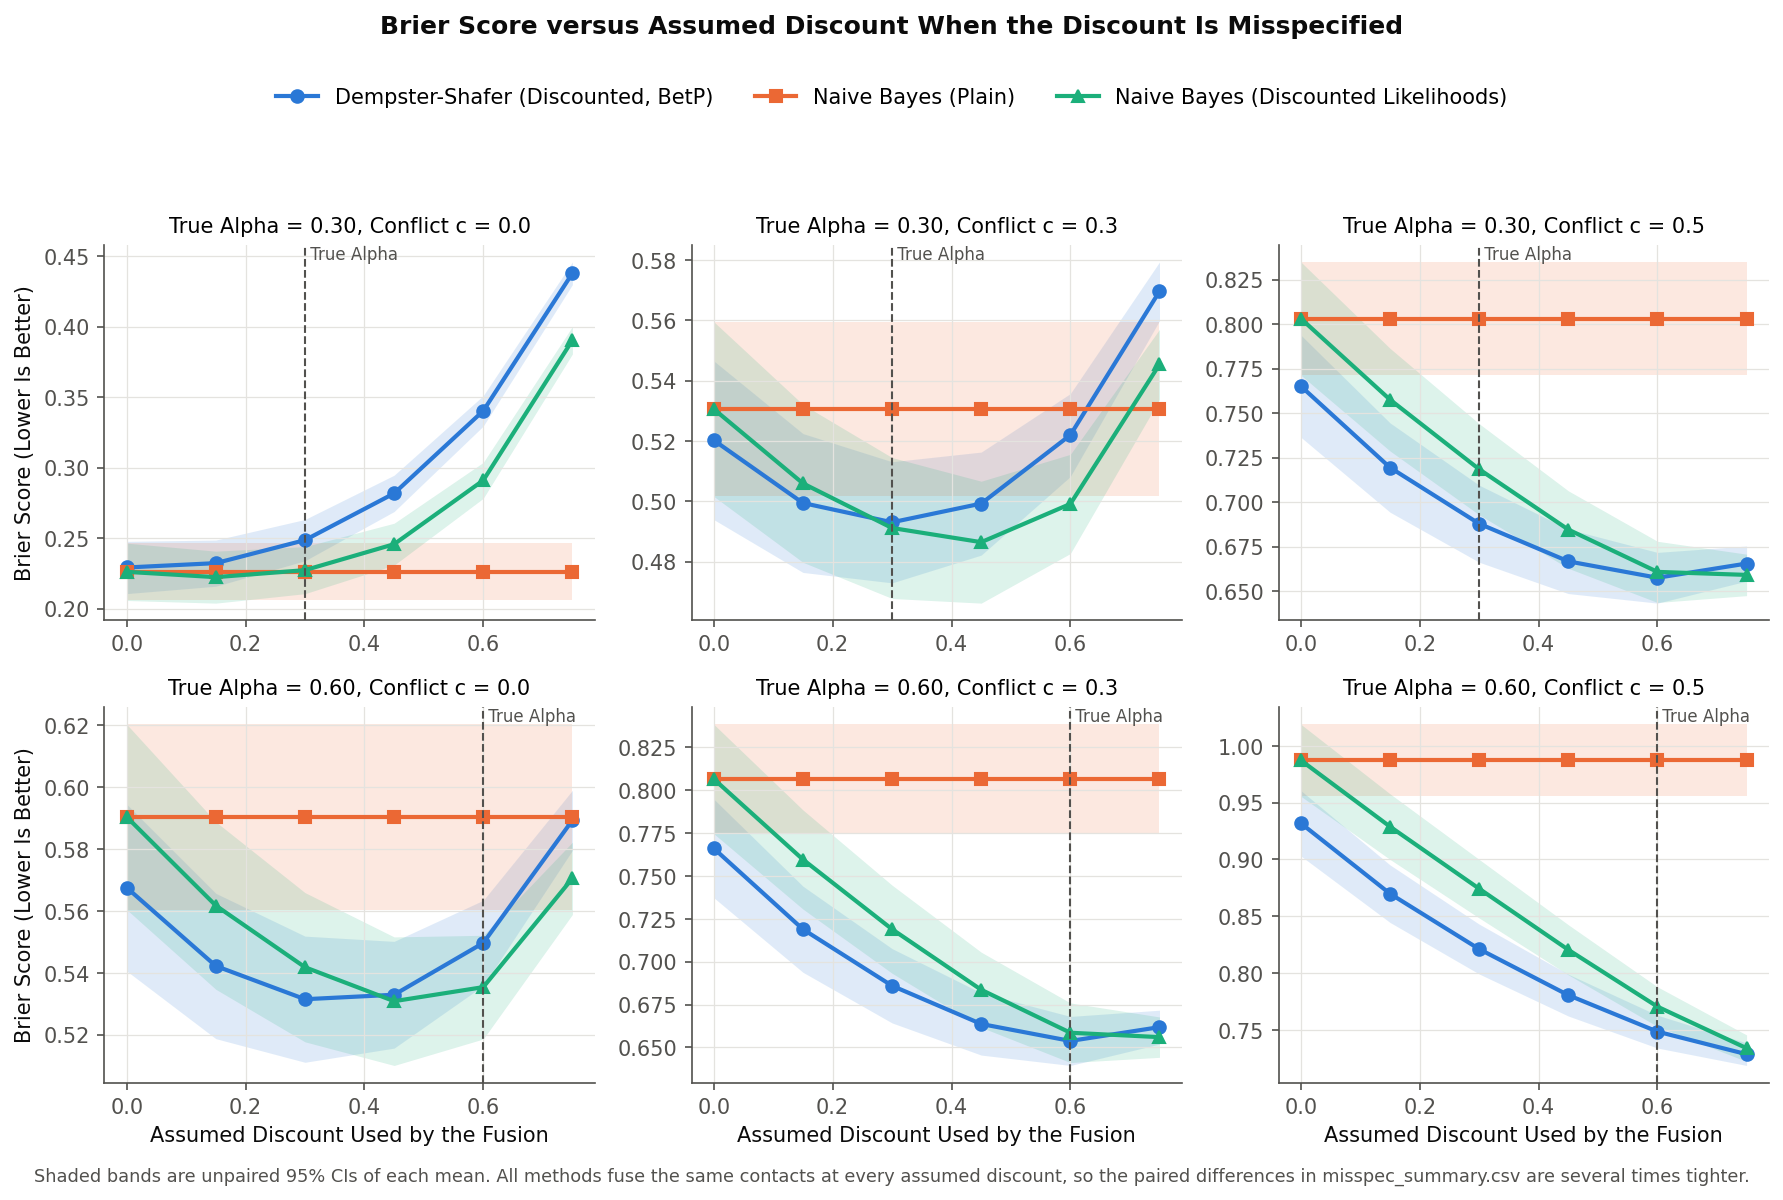

In [12]:
display(Image(filename=os.path.join("results", "fig_misspecified_discount.png")))

The two methods fail in opposite directions. A discount that is too small, which means trusting a sensor more than it deserves, costs discounted Bayes about twice as much as it costs evidence fusion, and evidence fusion is better calibrated in most of those cells. A discount that is too large costs evidence fusion more, because the extra mass it moves to Θ is shared evenly at decision time and flattens every forecast. The best discount for evidence fusion is also not the true malfunction rate. It is lower when there is no conflict and higher when there is heavy conflict, because the discount that calibrates best absorbs every uninformative or misleading report, including decoys the model is never told about. In practice the discount is a tuning parameter that would have to be fitted on data, not read off a sensor specification.

---

## **7. Preliminary Reading and Modeling Assumptions**

Accuracy is essentially identical across all 36 cells, so the comparison is decided by calibration. Against plain naive Bayes, evidence fusion is significantly better calibrated whenever conflict or unreliability is substantial, and the paired Brier gap reaches about 0.29 in the least reliable, most conflicting cell. With reliable sensors and little conflict it is slightly worse, because the mass it holds on Θ is unnecessary caution. When the Bayesian likelihoods are discounted by the same rate, most of the advantage disappears and a crossover remains. Discounted Bayes is better at conflict levels of 0.1 and below, and evidence fusion is better at 0.3 and above whenever any discount is applied. This supports the counter explanation named in the outline in part. Discounting carries most of the benefit, and Dempster's rule adds a smaller gain under high unmodeled conflict.

Four modeling assumptions shape these results. The closed world assumption removes conflict mass by renormalization rather than treating it as evidence of an unlisted class. Both methods assume the three sensor reports are independent given the class, so a single deception that fools two sensors at once would violate the model. Discounting is the correct model of unreliability in this simulator because the simulator generates unreliability that way. Section 6 tests what happens when the discount is wrong, and shows that the advantage over plain Bayes mostly survives while the comparison with discounted Bayes depends on the direction of the error. The Bayesian prior is uniform, which keeps the baseline neutral but ignores any operational base rates.